In [11]:
from IPython.core.display import HTML

# Define a largura desejada em pixels
largura = 10000

# Configura a largura da área de exibição
display(HTML(f"<style>.container {{ width:{largura}px !important; }}</style>"))

In [31]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:150% !important; }</style>"))
import warnings
warnings.simplefilter('ignore')

import pandas as pd
import matplotlib.pyplot as plot
import matplotlib.dates as mdates
import seaborn as sns
from plotly.offline import plot as plt
import plotly.graph_objs as go
import plotly.io as pio
import plotly.express as px
import time
from datetime import datetime, timedelta, date
import teradata
import  businessdays as bzd
from pandasql import sqldf
import pygwalker as pyg
import ipywidgets as widgets
from IPython.display import display

In [36]:

start = time.time() 
system = "TERADBAWS.sicredi.net"
user = "P_USR_DL_GESTAO_RECURSOS"
passw = "JAW0b71329aadade35365afc6X"
udaExec = teradata.UdaExec (appName="TESTE", version="1.0", logConsole=False)
session = udaExec.connect(method="odbc", system=system,
        username=user, password=passw, Authentication="TDNEGO");


select_feriados = "Select DT from dl_Gestao_recursos.bas_cad_fer where tipo in ('3','2')"
feriados = pd.read_sql(select_feriados, session)
cal = bzd.Calendar(holidays=feriados.DT,weekdays=['Sunday','Saturday'])

data_inicial = cal.offset(datetime.now(),-180  )###DATA PADRÃO D-180
data_inicial = data_inicial.strftime('%Y-%m-%d') ###DATA PADRÃO D-180

data_final = cal.offset(datetime.now(),-4 )###DATA PADRÃO D-1
data_final = data_final.strftime('%Y-%m-%d') ###DATA PADRÃO D-1

data = data_final
data_a = cal.offset(data,-5).strftime('%Y-%m-%d') ###DATA PADRÃO D-1
data_b = cal.offset(data,-20).strftime('%Y-%m-%d') ###DATA PADRÃO D-1
data_c = cal.offset(data,-60).strftime('%Y-%m-%d') ###DATA PADRÃO D-1
data_d = cal.offset(data,-50).strftime('%Y-%m-%d') ###DATA PADRÃO D-1


#data_inicial='2023-01-01'
#data_final='2023-07-25'

In [40]:
Select = f"""
        SELECT VAR.DTPOS, VAR.NOMECARTEIRA, VAR.CODCARTEIRAN2, VAR.CODCARTEIRAN3, DECODE(VAR.GRUPO,'Total', 'TOTAL',DECODE(VAR.CODCARTEIRAN2,'Arbitragem', 'ARBITRAGEM',VAR.CODCARTEIRAN3)) as Estrategia, VAR.var, VAR.var21, VAR.estresse, VAR.Cvar, VAR.ES 
        ,PL.VL_PATRLIQTOT1, VAR.CVAR/PL.VL_PATRLIQTOT1 AS CVAR_PL, VAR/PL.VL_PATRLIQTOT1 AS VAR_PL
        FROM DL_GESTAO_RECURSOS.VAR_ESTRATEGIA_SAS VAR
        left join dl_Gestao_recursos.sac_cl_patrsint pl on pl.dt = VAR.DTPOS AND VAR.NOMECARTEIRA = PL.CLCLI_CD
        WHERE VAR.DTPOS >- '{data_inicial}'  and ((VAR.codproduto is null and (case when VAR.CODCARTEIRAN2 = 'Arbitragem' then VAR.CODCARTEIRAN3 ELSE NULL END IS NULL)
        and DECODE(VAR.CODCARTEIRAN2,'Arbitragem', VAR.CODCARTEIRAN2,VAR.CODCARTEIRAN3) is not null) OR (VAR.GRUPO = 'Total'))
        """

df_var = pd.read_sql(Select, session) 
df_var.DtPos = pd.to_datetime(df_var.DtPos, format='%Y-%m-%d')
df_var = df_var.sort_values(by = ['DtPos', 'NomeCarteira','Estrategia'])
display(df_var)

,DtPos,NomeCarteira,CodCarteiraN2,CodCarteiraN3,Estrategia,VaR,VaR21,Estresse,CVaR,ES,VL_PATRLIQTOT1,CVAR_PL,VAR_PL
28581,2023-09-29,FAPI COMPOSTO,Ope. Compromissada,COMPROMISSADA,COMPROMISSADA,NaN,NaN,-98.297547,NaN,NaN,7.656254e+07,NaN,NaN
26456,2023-09-29,FAPI COMPOSTO,Inst. Financeira,EMISSAO IF,EMISSAO IF,-22.234607,-101.891769,-72.157071,-3.859769,-27.883094,7.656254e+07,-5.041328e-08,-2.904111e-07
29483,2023-09-29,FAPI COMPOSTO,Cia. Capital Aberto,EMISSAO PJ,EMISSAO PJ,-165.275361,-757.386850,-1520.075171,34.137134,-207.261970,7.656254e+07,4.458726e-07,-2.158698e-06
28090,2023-09-29,FAPI COMPOSTO,None,None,TOTAL,-4350.551726,-19936.732599,-97937.015588,-4350.551726,-5455.767377,7.656254e+07,-5.682351e-05,-5.682351e-05
27031,2023-09-29,FAPI COMPOSTO,TPF Casadas,TPF-ESTRUT,TPF-ESTRUT,-1007.278423,-4615.929619,-2119.419602,-221.136542,-1263.167779,7.656254e+07,-2.888313e-06,-1.315628e-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...
14093,2025-01-08,MASTER SELIC,Ope. Compromissada,COMPROMISSADA,COMPROMISSADA,NaN,NaN,-306.231132,NaN,NaN,6.224831e+07,NaN,NaN
13220,2025-01-08,MASTER SELIC,None,None,TOTAL,-45222.012259,-207233.294253,-203894.979523,-45222.012259,-56710.227745,6.224831e+07,-7.264777e-04,-7.264777e-04
14958,2025-01-08,MASTER SELIC,TPF Casadas,TPF-ESTRUT,TPF-ESTRUT,-42013.608794,-192530.542517,-192560.482249,-41450.297555,-52686.760365,6.224831e+07,-6.658863e-04,-6.749357e-04
15811,2025-01-08,MASTER SELIC,TPF Carteira,TPF_CART,TPF_CART,-1132.296170,-5188.832907,-7573.624950,-196.713961,-1419.945077,6.224831e+07,-3.160149e-06,-1.818999e-05


In [ ]:
walker = pyg.walk(df_var)

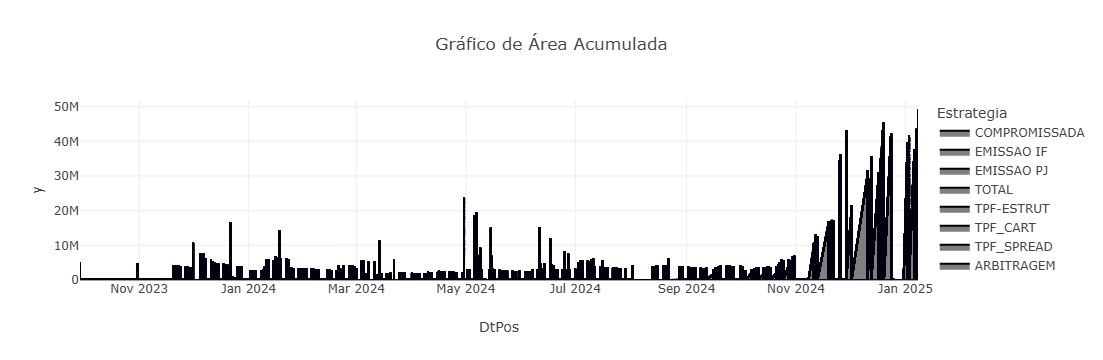

In [41]:
fig = px.area(df_var, x='DtPos', y=df_var.VaR*-1, color='Estrategia', title='Gráfico de Área Acumulada')
fig.show()

Dropdown(description='Nome Carteira:', options=('FI RESG FACIL', 'FIRF MAPFRE', 'FIA PETROBRAS', 'FIA ESG ALOC…

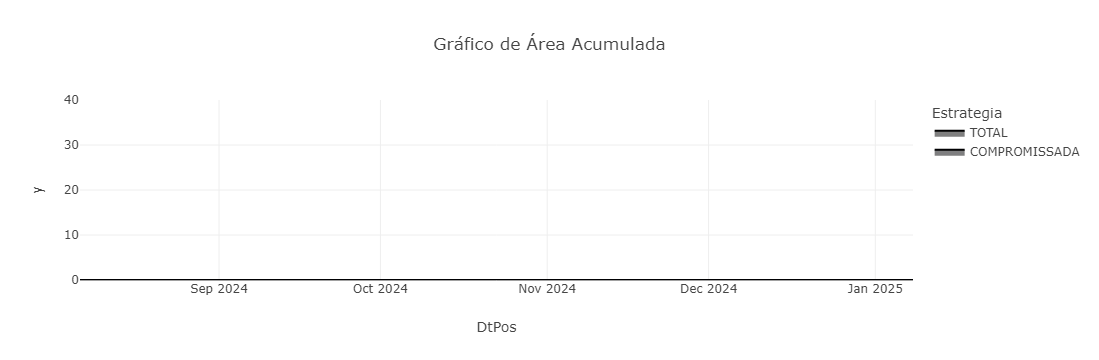

In [39]:
dropdown = widgets.Dropdown(
    options=df_var["NomeCarteira"].unique(),
    description='Nome Carteira:',
    disabled=False,
)

# Função para atualizar o gráfico com base na seleção do menu suspenso
def update_plot(change):
    df_filtro = df_var[df_var["NomeCarteira"] == dropdown.value]
    df_filtro = df_filtro.sort_values('DtPos')
    fig = px.area(df_filtro, x='DtPos', y=df_filtro.VaR*-1, color='Estrategia', title='Gráfico de Área Acumulada')
    fig.show()

# Conectando a função de atualização ao menu suspenso
dropdown.observe(update_plot, names='value')

# Exibindo o menu suspenso
display(dropdown)

# Exibindo o gráfico inicial
update_plot(None)